# Event generation: simulated vs real

How an event camera turns brightness change into events. Events are simulated from a real 240 fps slow-motion video of a fidget spinner and compared with what our DAVIS346 recorded of the same spinner at the same time. Both cameras were mounted side by side; in both clips the spinner is held still for about a second, then flicked and left to spin down. Sections whose data is missing print `SKIPPED: <reason>`.

## Setup

In [1]:
import os, sys
if "google.colab" in sys.modules:
    REPO = "/content/event-perception"
    if not os.path.exists(REPO):
        !git clone https://github.com/allusson/event-perception.git {REPO}
    %cd {REPO}
    !pip install -q -e .
    sys.path.insert(0, REPO)
else:
    # local: assumes `pip install -e ".[deblur]"` was run from the repo root
    os.chdir(os.path.dirname(os.path.abspath("")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd())

In [2]:
import dataclasses
import time
import numpy as np
import matplotlib.pyplot as plt

from evcam.sources import load_davis, load_video
from evcam.simulate import simulate_events
from evcam.representations import event_image
from evcam.viz import show_events


def disp(img):
    # display only: linear intensity -> gamma 1/2.2
    return np.clip(img, 0, 1) ** (1 / 2.2)


def in_window(ev, t0_us, t1_us):
    return ev[(ev["t"] >= t0_us) & (ev["t"] < t1_us)]


def crop(img, box):
    return img if box is None else img[box[1]:box[3], box[0]:box[2]]


T_NOTEBOOK = time.time()

## 0. Parameters

`VIDEO_START_FRAME` and `DAVIS_START_MS` mark the start of the flick in each clip and are read off the previews in section 3.1. Crop boxes are `(x0, y0, x1, y1)` in pixels, `None` for the full frame.

In [3]:
VIDEO_PATH = "data/video_data/spinner.mov"       # iPhone slow motion (or .mp4)
DAVIS_PATH = "data/davis_data/spinner.aedat4"
CAPTURE_FPS = 240                                # true capture rate of the phone clip
VIDEO_T_START_S = 0.0                            # part of the phone clip to load, s
VIDEO_DURATION_S = 8.0
C_SIM = 0.2                                      # contrast threshold of the simulation

VIDEO_START_FRAME = None       # first phone frame where the spinner has moved (section 3.1)
DAVIS_START_MS = None          # start of the first DAVIS window that lights up, ms (section 3.1)
VIDEO_PREVIEW_START_S = 0.2    # where the phone preview begins, s on the loaded clip's clock
DAVIS_PREVIEW_START_S = 3      # where the DAVIS preview begins, s on the DAVIS clock

VIDEO_CROP = None              # (x0, y0, x1, y1) around the spinner in the phone frames
DAVIS_CROP = None              # (x0, y0, x1, y1) around the spinner in the DAVIS events
ROW_TIMES_MS = (0, 50, 150, 300)   # times since motion start shown side by side
WINDOW_MS = 5                  # event image window

## 1. Event generation model

Per pixel $\mathbf{x}$ the log intensity is

$$\ell(\mathbf{x}, t) = \log\big(I(\mathbf{x}, t) + \varepsilon\big)$$

$I$: linear intensity, $\varepsilon = 10^{-3}$. Each pixel keeps a reference level $\ell_\text{ref}(\mathbf{x})$, initialized from the first frame. Between frames $i$ and $i+1$ (times $t_i$, $t_{i+1}$) $\ell$ is linearly interpolated, and an event is emitted each time

$$\big|\ell(\mathbf{x}, t) - \ell_\text{ref}(\mathbf{x})\big| = c,$$

with polarity $p = \operatorname{sign}(\ell - \ell_\text{ref})$, at the crossing time

$$t_k = t_i + \frac{\ell_\text{ref} + p\,c - \ell_i}{\ell_{i+1} - \ell_i}\,(t_{i+1} - t_i),$$

after which $\ell_\text{ref} \leftarrow \ell_\text{ref} + p\,c$. $c$: contrast threshold, $\ell_i$, $\ell_{i+1}$: log intensity of the pixel in the two frames. The model is accurate only when the motion between frames is small (high frame rate).

## 2. Video to events

Loads the phone clip with `load_video(VIDEO_PATH, capture_fps=CAPTURE_FPS)`, from `VIDEO_T_START_S` for `VIDEO_DURATION_S`: iPhone slow-motion files store a 30 fps playback rate, so container timestamps would be 8x too long. `load_video` converts the frames to linear intensity (inverse sRGB) and resizes them to the DAVIS346 resolution. Events are simulated at $c$ = `C_SIM`; the figures show four frames with the simulated events over `WINDOW_MS` around each, the event rate over time, and the event count for $c \in \{0.1, 0.2, 0.4\}$ over the first 2 s. 240 fps at 346x260 is about 86 MB per second of video, so trim the phone clip to a few seconds around the flick before transferring it.

spinner.mov: container fps 30.0, capture fps used for timestamps 240


loaded 1244 frames, 5.18 s from 0.0 s


c = 0.2: 18,264,467 events (50.0% ON) simulated in 2.3 s


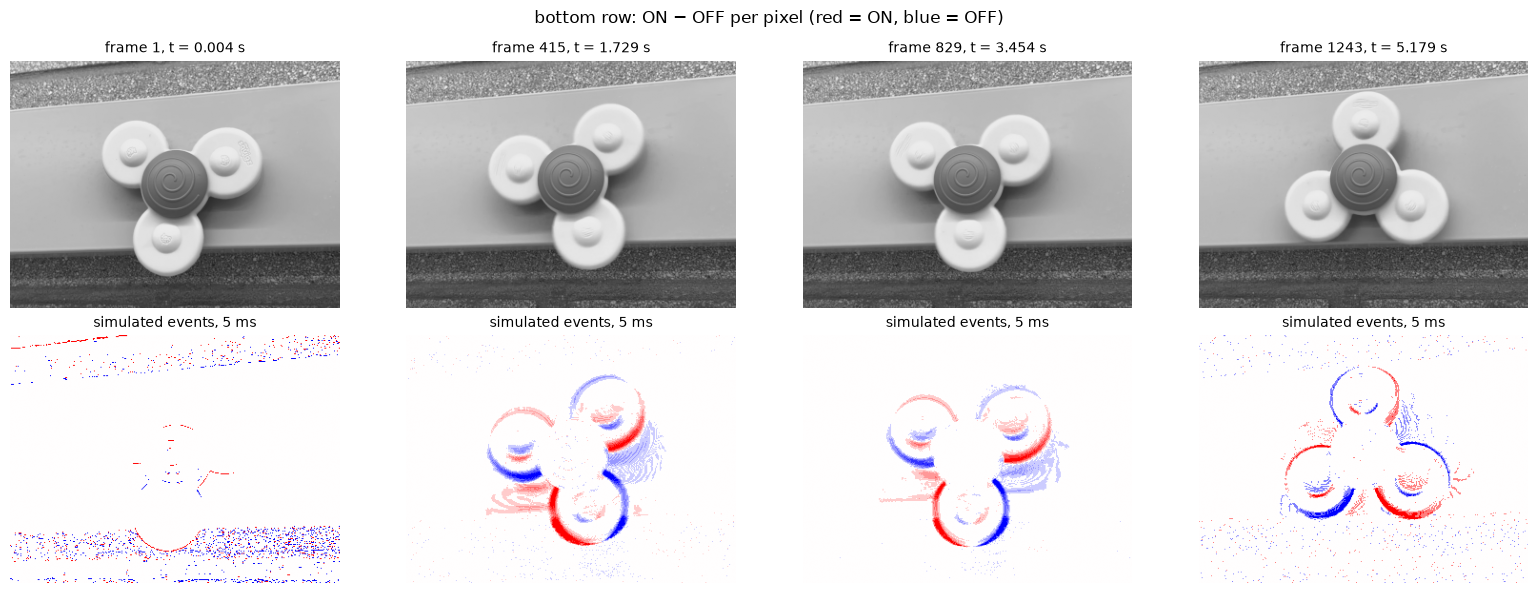

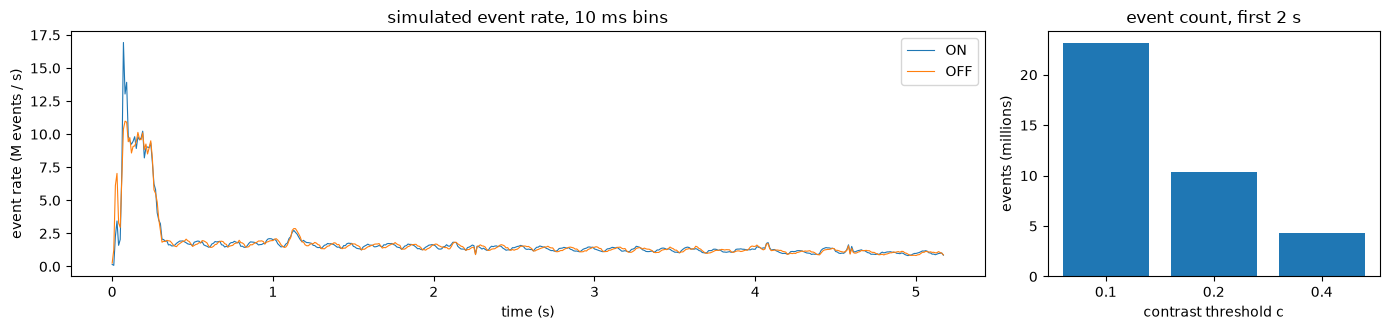

c = 0.1: 23,146,140 events   c x count = 2,314,614
c = 0.2: 10,325,555 events   c x count = 2,065,111
c = 0.4:  4,274,302 events   c x count = 1,709,721


In [4]:
video = sim = None
if not os.path.exists(VIDEO_PATH):
    print(f"SKIPPED: {VIDEO_PATH} not found")
else:
    video = load_video(VIDEO_PATH, capture_fps=CAPTURE_FPS, t_start_s=VIDEO_T_START_S, duration_s=VIDEO_DURATION_S)
    print(f"loaded {video.n_frames} frames, {video.n_frames / CAPTURE_FPS:.2f} s from {VIDEO_T_START_S} s")
    t0 = time.time()
    sim = simulate_events(video, c=C_SIM)
    print(f"c = {C_SIM}: {sim.n_events:,} events ({np.mean(sim.events['p'] == 1):.1%} ON) "
          f"simulated in {time.time() - t0:.1f} s")

    H, W = video.shape
    idx = np.linspace(1, video.n_frames - 1, 4).astype(int)
    fig, ax = plt.subplots(2, 4, figsize=(16, 6))
    for j, i in enumerate(idx):
        t = video.frame_t[i]
        ax[0, j].imshow(disp(video.frames[i]), cmap="gray", vmin=0, vmax=1)
        ax[0, j].set_title(f"frame {i}, t = {t / 1e6:.3f} s", fontsize=10)
        show_events(ax[1, j], event_image(in_window(sim.events, t - WINDOW_MS * 500, t + WINDOW_MS * 500), (W, H, 2)),
                    colorbar=False, title=f"simulated events, {WINDOW_MS} ms", fontsize=10)
    for a in ax.ravel(): a.axis("off")
    fig.suptitle("bottom row: ON − OFF per pixel (red = ON, blue = OFF)"); plt.tight_layout(); plt.show()

    head = dataclasses.replace(video, frames=video.frames[:2 * CAPTURE_FPS], frame_t=video.frame_t[:2 * CAPTURE_FPS])
    counts = {c: simulate_events(head, c=c).n_events for c in (0.1, 0.2, 0.4)}    # first 2 s
    edges = np.arange(video.frame_t[0], video.frame_t[-1] + 10000, 10000)
    fig, ax = plt.subplots(1, 2, figsize=(14, 3.4), gridspec_kw={"width_ratios": [2.2, 0.8]})
    for pol, name in ((1, "ON"), (0, "OFF")):
        h, _ = np.histogram(sim.events["t"][sim.events["p"] == pol], edges)
        ax[0].plot(edges[:-1] / 1e6, h / 1e4, lw=0.8, label=name)      # events per 10 ms -> M events / s
    ax[0].set_xlabel("time (s)"); ax[0].set_ylabel("event rate (M events / s)")
    ax[0].set_title("simulated event rate, 10 ms bins"); ax[0].legend()
    ax[1].bar([str(c) for c in counts], [n / 1e6 for n in counts.values()])
    ax[1].set_xlabel("contrast threshold c"); ax[1].set_ylabel("events (millions)"); ax[1].set_title("event count, first 2 s")
    plt.tight_layout(); plt.show()
    for c, n in counts.items():
        print(f"c = {c}: {n:>10,} events   c x count = {c * n:,.0f}")

$c \times$ count falls as $c$ grows: a larger $c$ discards more of the change below the threshold left at each pixel.

## 3. Simulated vs real events

### 3.1 Motion start, picked by hand

The phone and the DAVIS start recording at different times, so the clips are aligned on the flick. The first figure covers each whole clip: the DAVIS event rate (10 ms bins) and the phone's mean absolute difference between consecutive frames. The flick is the first big jump in each curve; set `VIDEO_PREVIEW_START_S` and `DAVIS_PREVIEW_START_S` just before it. The previews then start there, on each clip's own clock: 40 phone frames, 40 consecutive 10 ms DAVIS event images, and the DAVIS event rate over the same span. While the spinner is held still there are almost no events, so the flick is the first DAVIS window that lights up and the first phone frame where the spinner has moved. Enter the two values as `VIDEO_START_FRAME` and `DAVIS_START_MS` in section 0 and re-run. The last figure shows one phone frame and the DAVIS events over the preview span with pixel axes, to read off `VIDEO_CROP` and `DAVIS_CROP`.

source davis, 346x260, 437 frames over 16.717 s, 26.0817 fps, 2,352,609 events over 16.810 s


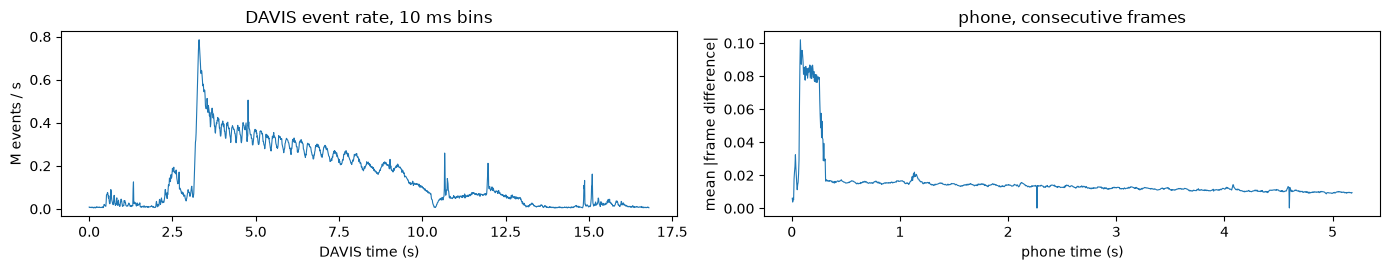

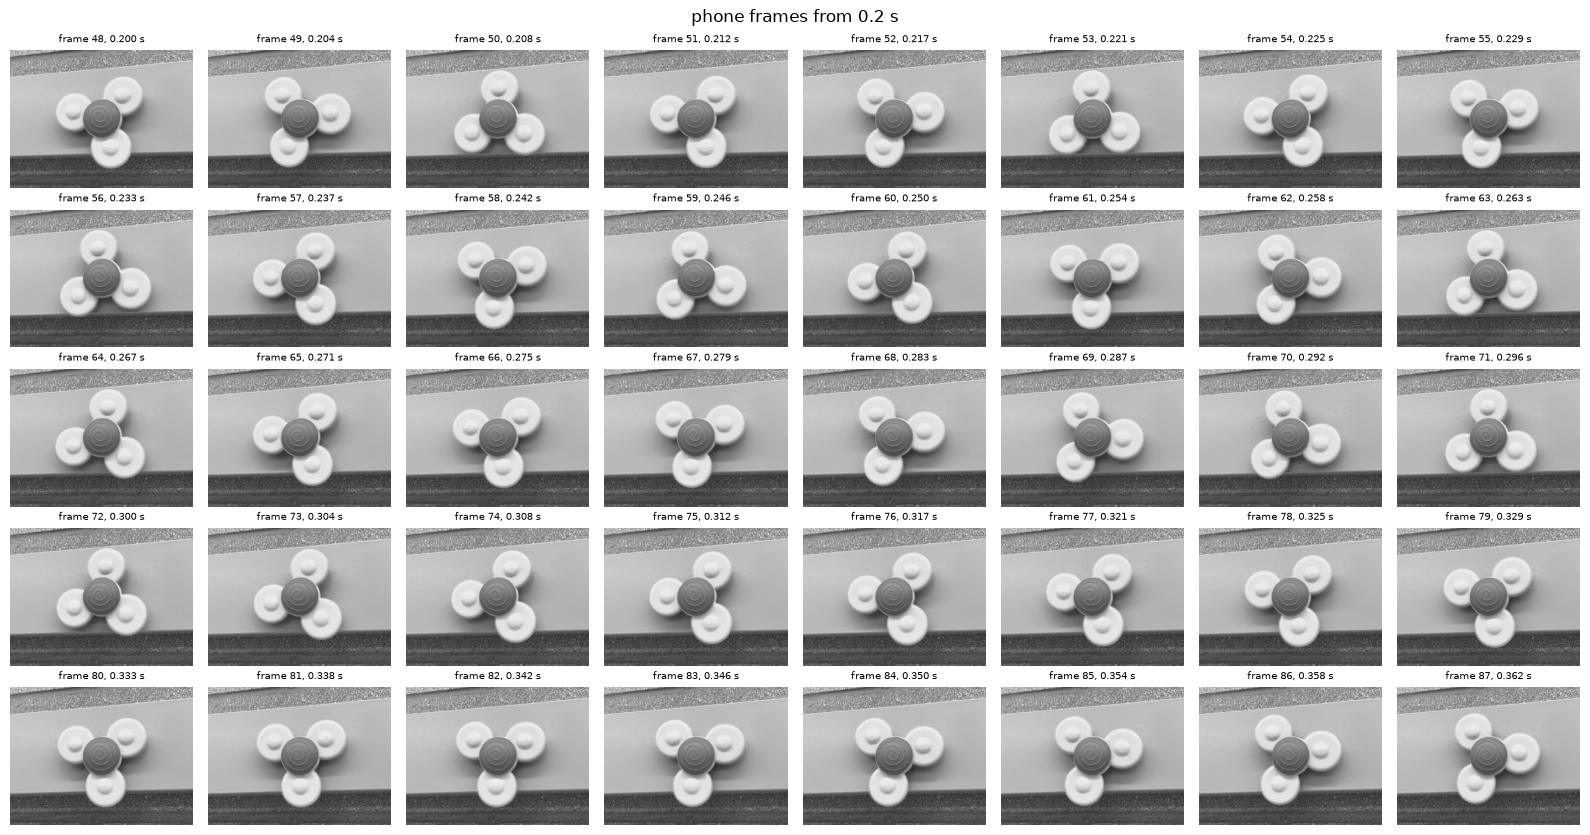

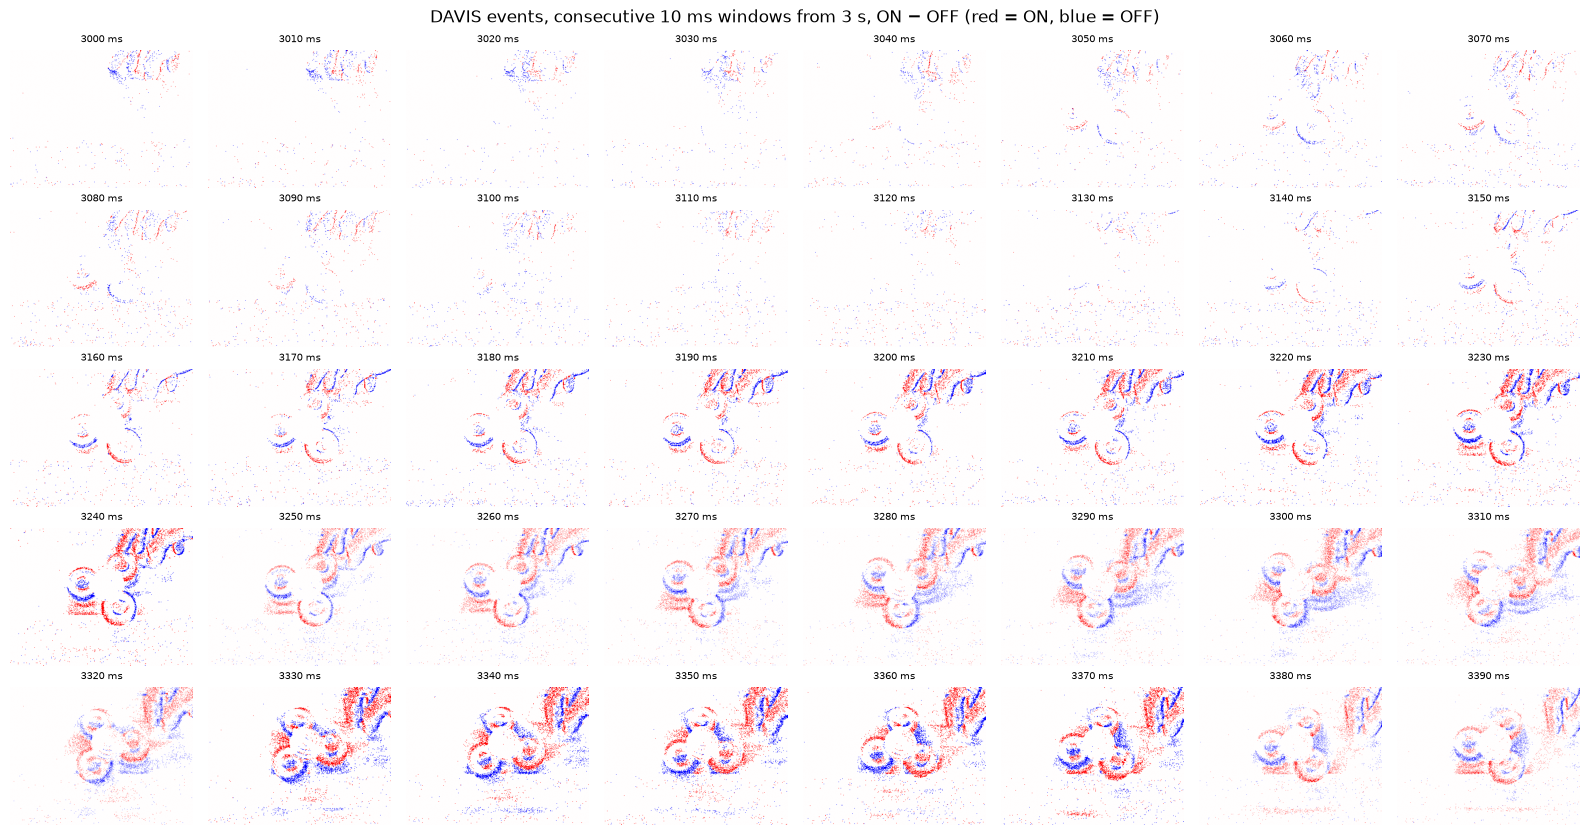

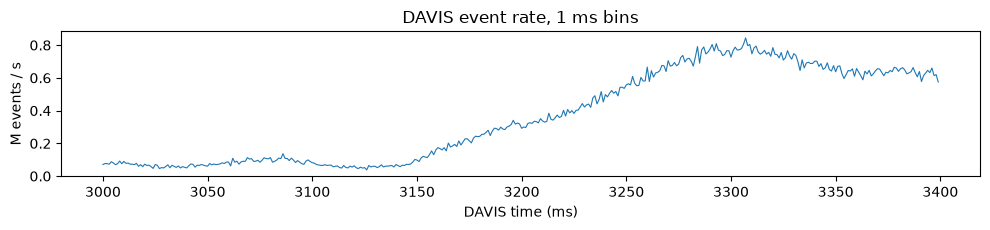

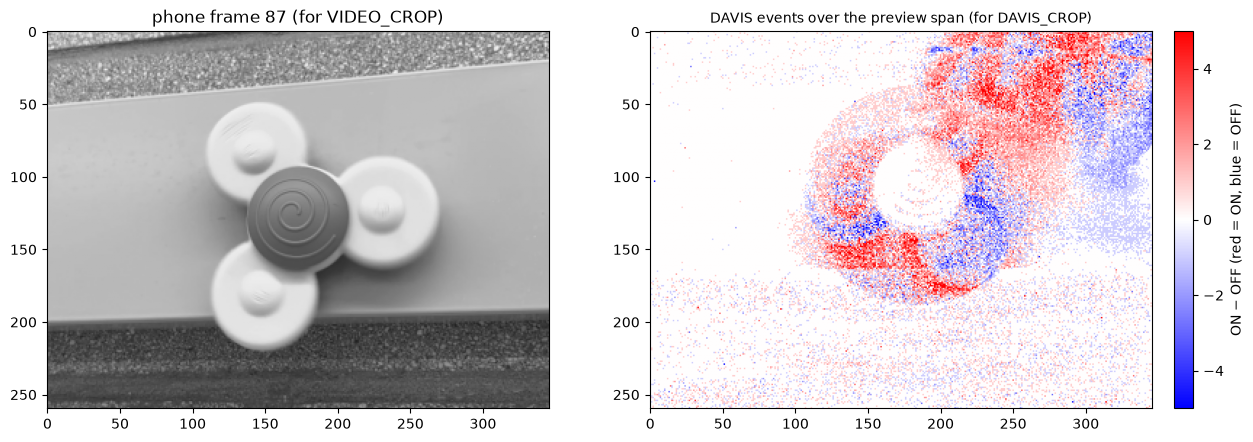

Set VIDEO_START_FRAME and DAVIS_START_MS in section 0 from the previews above, then re-run.


In [5]:
N_PREVIEW, DAVIS_STEP_MS = 40, 10
davis = None
if video is None:
    print(f"SKIPPED: {VIDEO_PATH} not found")
if not os.path.exists(DAVIS_PATH):
    print(f"SKIPPED: {DAVIS_PATH} not found")
elif video is not None:
    davis = load_davis(DAVIS_PATH)
    print(davis.summary())

if davis is not None:
    H, W = video.shape
    Hd, Wd = davis.shape
    fig, ax = plt.subplots(1, 2, figsize=(14, 2.8))
    edges = np.arange(0, davis.events["t"][-1] + 10000, 10000)
    ax[0].plot(edges[:-1] / 1e6, np.histogram(davis.events["t"], edges)[0] / 1e4, lw=0.8)   # per 10 ms -> M / s
    ax[0].set_xlabel("DAVIS time (s)"); ax[0].set_ylabel("M events / s"); ax[0].set_title("DAVIS event rate, 10 ms bins")
    mad = [np.abs(video.frames[k + 1] - video.frames[k]).mean() for k in range(video.n_frames - 1)]
    ax[1].plot(video.frame_t[1:] / 1e6, mad, lw=0.8)
    ax[1].set_xlabel("phone time (s)"); ax[1].set_ylabel("mean |frame difference|")
    ax[1].set_title("phone, consecutive frames")
    plt.tight_layout(); plt.show()

    k0 = int(round(VIDEO_PREVIEW_START_S * CAPTURE_FPS))
    ks = range(k0, min(k0 + N_PREVIEW, video.n_frames))
    fig, ax = plt.subplots(5, 8, figsize=(16, 8.5))
    for a, k in zip(ax.ravel(), ks):
        a.imshow(disp(video.frames[k]), cmap="gray", vmin=0, vmax=1)
        a.set_title(f"frame {k}, {video.frame_t[k] / 1e6:.3f} s", fontsize=7)
    for a in ax.ravel(): a.axis("off")
    fig.suptitle(f"phone frames from {VIDEO_PREVIEW_START_S} s"); plt.tight_layout(); plt.show()

    t_p0 = int(round(DAVIS_PREVIEW_START_S * 1e6))
    starts = t_p0 + np.arange(N_PREVIEW) * DAVIS_STEP_MS * 1000
    fig, ax = plt.subplots(5, 8, figsize=(16, 8.5))
    for a, t in zip(ax.ravel(), starts):
        show_events(a, event_image(in_window(davis.events, t, t + DAVIS_STEP_MS * 1000), (Wd, Hd, 2)),
                    colorbar=False, title=f"{t / 1e3:.0f} ms", fontsize=7)
        a.axis("off")
    fig.suptitle(f"DAVIS events, consecutive {DAVIS_STEP_MS} ms windows from {DAVIS_PREVIEW_START_S} s, "
                 "ON − OFF (red = ON, blue = OFF)")
    plt.tight_layout(); plt.show()

    span = in_window(davis.events, starts[0], starts[-1] + DAVIS_STEP_MS * 1000)
    edges = np.arange(starts[0], starts[-1] + DAVIS_STEP_MS * 1000 + 1, 1000)
    fig, ax = plt.subplots(figsize=(10, 2.4))
    ax.plot(edges[:-1] / 1e3, np.histogram(span["t"], edges)[0] / 1e3, lw=0.8)    # events per ms -> M events / s
    ax.set_xlabel("DAVIS time (ms)"); ax.set_ylabel("M events / s"); ax.set_title("DAVIS event rate, 1 ms bins")
    plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    ax[0].imshow(disp(video.frames[ks[-1]]), cmap="gray", vmin=0, vmax=1)
    ax[0].set_title(f"phone frame {ks[-1]} (for VIDEO_CROP)")
    show_events(ax[1], event_image(span, (Wd, Hd, 2)), title="DAVIS events over the preview span (for DAVIS_CROP)")
    plt.tight_layout(); plt.show()

ready = davis is not None and VIDEO_START_FRAME is not None and DAVIS_START_MS is not None
if davis is not None and not ready:
    print("Set VIDEO_START_FRAME and DAVIS_START_MS in section 0 from the previews above, then re-run.")

### 3.2 Alignment

Shifts both clips so the motion starts at $t = 0$. The precision is about one phone frame (4.2 ms) and the 10 ms DAVIS preview window.

In [6]:
if not ready:
    print("SKIPPED: set VIDEO_START_FRAME and DAVIS_START_MS (section 3.1)")
else:
    t_video0 = int(video.frame_t[VIDEO_START_FRAME])
    t_davis0 = int(round(DAVIS_START_MS * 1e3))
    video_t = video.frame_t - t_video0                         # phone frame times since motion start, us
    sim_ev = sim.events.copy(); sim_ev["t"] -= t_video0
    real_ev = davis.events.copy(); real_ev["t"] -= t_davis0
    print(f"phone: motion starts at frame {VIDEO_START_FRAME}, offset {t_video0 / 1e3:.1f} ms")
    print(f"DAVIS: motion starts at {DAVIS_START_MS} ms, offset {t_davis0 / 1e3:.1f} ms")

SKIPPED: set VIDEO_START_FRAME and DAVIS_START_MS (section 3.1)


### 3.3 Side by side

One row per time in `ROW_TIMES_MS` after the motion start: the nearest phone frame, the simulated events and the real DAVIS events, each event image over `WINDOW_MS` centred on that time, cropped to `VIDEO_CROP` and `DAVIS_CROP`. The comparison is by eye; the two cameras are not spatially aligned.

In [7]:
if not ready:
    print("SKIPPED: set VIDEO_START_FRAME and DAVIS_START_MS (section 3.1)")
else:
    half = WINDOW_MS * 500
    fig, ax = plt.subplots(len(ROW_TIMES_MS), 3, figsize=(12, 3.4 * len(ROW_TIMES_MS)), squeeze=False)
    for r, t_ms in enumerate(ROW_TIMES_MS):
        t = t_ms * 1000
        i = int(np.argmin(np.abs(video_t - t)))
        ax[r, 0].imshow(crop(disp(video.frames[i]), VIDEO_CROP), cmap="gray", vmin=0, vmax=1)
        ax[r, 0].set_title(f"phone frame {i}, {video_t[i] / 1e3:.1f} ms", fontsize=10)
        show_events(ax[r, 1], crop(event_image(in_window(sim_ev, t - half, t + half), (W, H, 2)), VIDEO_CROP),
                    colorbar=False, title=f"simulated, c = {C_SIM}, {t_ms} ms", fontsize=10)
        show_events(ax[r, 2], crop(event_image(in_window(real_ev, t - half, t + half), (Wd, Hd, 2)), DAVIS_CROP),
                    colorbar=False, title=f"DAVIS, {t_ms} ms", fontsize=10)
    for a in ax.ravel(): a.axis("off")
    fig.suptitle(f"{WINDOW_MS} ms event windows, time since motion start, ON − OFF (red = ON, blue = OFF)"); plt.tight_layout(); plt.show()

SKIPPED: set VIDEO_START_FRAME and DAVIS_START_MS (section 3.1)


### 3.4 Event rate

Real and simulated event rate over time since the motion start, counted inside each crop and divided by the crop area (events per pixel per second), in `WINDOW_MS` bins.

In [8]:
def rate_per_pixel(ev, box, shape, edges):
    # events per pixel per second inside box, per time bin
    h, w = shape
    x0, y0, x1, y1 = (0, 0, w, h) if box is None else box
    ev = ev[(ev["x"] >= x0) & (ev["x"] < x1) & (ev["y"] >= y0) & (ev["y"] < y1)]
    return np.histogram(ev["t"], edges)[0] / ((x1 - x0) * (y1 - y0) * np.diff(edges) / 1e6)


if not ready:
    print("SKIPPED: set VIDEO_START_FRAME and DAVIS_START_MS (section 3.1)")
else:
    t_lo = max(video_t[0], real_ev["t"][0])
    t_hi = min(video_t[-1], real_ev["t"][-1])
    edges = np.arange(t_lo, t_hi, WINDOW_MS * 1000)
    fig, ax = plt.subplots(figsize=(11, 3.6))
    ax.plot(edges[:-1] / 1e6, rate_per_pixel(real_ev, DAVIS_CROP, davis.shape, edges), lw=0.8, label="DAVIS (real)")
    ax.plot(edges[:-1] / 1e6, rate_per_pixel(sim_ev, VIDEO_CROP, video.shape, edges), lw=0.8,
            label=f"simulated, c = {C_SIM}")
    ax.set_xlabel("time since motion start (s)"); ax.set_ylabel("events / pixel / s")
    ax.set_title(f"event rate inside the crops, {WINDOW_MS} ms bins"); ax.legend()
    plt.tight_layout(); plt.show()

SKIPPED: set VIDEO_START_FRAME and DAVIS_START_MS (section 3.1)


In [9]:
print(f"notebook runtime {time.time() - T_NOTEBOOK:.0f} s")

notebook runtime 56 s


## References

1. H. Rebecq, D. Gehrig, D. Scaramuzza, "ESIM: an Open Event Camera Simulator", Conference on Robot Learning (CoRL) 2018.